### Experiment with Variational Autoencoder- Fashion MNIST Dataset

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms
from torchinfo import summary
import mlflow
import matplotlib.pyplot as plt
import torch.nn.functional as F



In [2]:
mlflow.set_tracking_uri("http://127.0.0.1:5000")

### Loading the Data 

In [3]:
transform = transforms.ToTensor()
data_path = '../data'
train_dataset = datasets.FashionMNIST(
    root=data_path,
    train=True,
    download=False,  # Already downloaded!
    transform=transform
)

test_dataset = datasets.FashionMNIST(
    root=data_path,
    train=False,
    download=False,
    transform=transform
)

### Hyper Parameters

In [4]:
# Hyperparameters:
epochs = 50
learning_rate = 0.01
batch_size = 32

### Architecture Parameters

In [5]:
latent_dim = 32
h1_e_nodes = 128
h1_d_nodes = 128
encoder_layers = 2
decoder_layers = 2

image_size = 28 * 28

In [ ]:
class VAE(nn.Module):
    def __init__(self,num_inputs=784, num_hidden1=256, num_latent = 32):
        super().__init__()
        self.fc1 = nn.Linear(num_inputs,num_hidden1)
        self.fc_mu = nn.Linear(num_hidden1,num_latent)
        self.fc_logvar = nn.Linear(num_hidden1,num_latent)

        self.decoder = nn.Sequential(
                nn.Linear(num_latent,num_hidden1),
                nn.ReLU(),
                nn.Linear(num_hidden1,num_inputs),
                nn.Sigmoid()
            )

    def encode(self,image):
        x = torch.relu(self.fc1(image))
        mu = self.fc_mu(x)
        logvar = self.fc_logvar(x)
        return mu, logvar

    def forward(self,image):
        mu, logvar = self.encode(image)
        z = self.reparameterize(mu,logvar)
        image_reconst = self.decoder(z)
        return image_reconst, mu, logvar
        

    def reparameterize(self,mu,logvar):
        std = torch.exp(0.5*logvar)
        eps = torch.randn_like(std)
        z = mu + eps*std
        return z

In [7]:
train_loader = DataLoader(train_dataset,shuffle=True,batch_size=batch_size)
test_loader = DataLoader(test_dataset,shuffle=False,batch_size=batch_size)
model = VAE()


In [8]:
mlflow.set_experiment("VAE_fashion_MNIST");

### VAE Loss Function

In [9]:
def vae_loss(x_reconst, x, mu, logvar):
    recon_loss = nn.functional.binary_cross_entropy(x_reconst, x, reduction='sum')
    kl_loss = -0.5*torch.sum(1+logvar-mu.pow(2)-logvar.exp())
    total_loss = recon_loss + kl_loss
    return total_loss, recon_loss, kl_loss


### Initializations

In [10]:
optimizer = optim.Adam(model.parameters(),lr=learning_rate)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device);

### Comparison Plotting function

In [11]:
def plot_original_vs_reconstructed_image(original,regenerated,curr_class):
    # Give the tensor of size 784 as an input 
    original = original.cpu().numpy().reshape(28, 28)
    regenerated = regenerated.cpu().numpy().reshape(28, 28)
    plt.figure(figsize=(8, 4))
    plt.suptitle(f"Epoch: {epoch+1} | Original vs Reconstructed | Label: {curr_class}")

    plt.subplot(1, 2, 1)
    plt.imshow(original)
    plt.title("Original")
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(regenerated)
    plt.title("Reconstructed")
    plt.axis('off')
    return plt

### Training Loop

In [13]:
avg_train_loss = 0
avg_train_reconstruction_loss = 0
avg_train_kl_loss = 0

avg_test_loss = 0
avg_test_reconstruction_loss = 0
avg_test_kl_loss = 0

# Select a fixed training image
fixed_image, fixed_image_label = test_dataset[10]
fixed_image = fixed_image.view(1, -1).to(device)

fixed_eps = torch.randn(1, latent_dim).to(device)

with mlflow.start_run(run_name = f"Trial 001 with {latent_dim}"):
    mlflow.log_params({
        "lr": learning_rate,
        "epochs": epochs,
        "batch_size": batch_size,

        "model": "Variational Autoencoder",
        "input_dim": 784,
        "latent_dim": latent_dim,
        "encoder_layers": encoder_layers,
        "decoder_layers": decoder_layers,

        "optimizer": "Adam",
        "loss_function": "BCE Loss + KL Loss",
        "activation": "ReLU",
        "output_activation": "Sigmoid",
        "dataset": "FashionMNIST"
    })
    for epoch in range(epochs):
        model.train()
        total_train_epoch_loss = 0
        total_train_epoch_recon_loss = 0
        total_train_epoch_kl_loss = 0
        for (images,_) in train_loader:
            images = images.view(images.size(0), -1).to(device)
            regenerated_image, mu, logvar = model(images)
            total_loss, train_recon_loss, train_kl_loss = vae_loss(regenerated_image, images, mu, logvar)

            optimizer.zero_grad()
            total_loss.backward()
            optimizer.step()

            total_train_epoch_loss +=total_loss.item()
            total_train_epoch_recon_loss +=train_recon_loss.item()
            total_train_epoch_kl_loss +=train_kl_loss.item()

        avg_train_loss = total_train_epoch_loss / len(train_loader.dataset)
        avg_train_reconstruction_loss = total_train_epoch_recon_loss / len(train_loader.dataset)
        avg_train_kl_loss = total_train_epoch_kl_loss / len(train_loader.dataset)
        if (epoch + 1) % 5 == 0 or epoch == 0:
            print(f"Epoch [{epoch+1}/{epochs}] - Total Loss: {avg_train_loss:.6f} | Recon Loss: {avg_train_reconstruction_loss:.6f} | KL Loss: {avg_train_kl_loss:.6f}")
            # Store the a testing image for tracking the regression progression 
            model.eval()
            with torch.no_grad():
                mu, logvar = model.encode(fixed_image)
                std = torch.exp(0.5 * logvar)
                z = mu + fixed_eps * std
                reconstructed = model.decoder(z)
            # Draw Image function
            label = f"Test Plot with mu + eps*std = {mu}+{fixed_eps}*{std}"
            plt = plot_original_vs_reconstructed_image(fixed_image,reconstructed,label)
            mlflow.log_figure(plt.gcf(),f"Epoch_{epoch+1}.png")
            plt.close()
        Reconstruction_KL_Ratio =  avg_train_reconstruction_loss / (avg_train_kl_loss + 1e-8)
        mlflow.log_metrics({'Total Train Loss':avg_train_loss,
        'Train Recon Loss': avg_train_reconstruction_loss,
        'Train KL Loss':avg_train_kl_loss,
        'Reconstruction_KL_Ratio':Reconstruction_KL_Ratio},step=epoch+1)
       
    # Training loop ends here, test section starts here.
    total_test_loss = 0
    total_test_epoch_recon_loss = 0
    total_test_epoch_kl_loss = 0

    model.eval()

    for (images_test,_) in test_loader:
        images_test = images_test.view(images_test.size(0), -1).to(device)
        with torch.no_grad():
            # Keeping test loss deterministic.
            mu_test, logvar_test = model.encode(images_test)
            reconstructed_test = model.decoder(mu_test)
            test_loss, test_recon_loss, test_kl_loss = vae_loss(reconstructed_test, images_test, mu_test, logvar_test)
            total_test_loss += test_loss.item()
            total_test_epoch_recon_loss +=test_recon_loss.item()
            total_test_epoch_kl_loss +=test_kl_loss.item()

    avg_test_loss = total_test_loss / len(test_loader.dataset)
    avg_test_reconstruction_loss = total_test_epoch_recon_loss / len(test_loader.dataset)
    avg_test_kl_loss = total_test_epoch_kl_loss / len(test_loader.dataset)
    Reconstruction_Test_KL_Ratio = (avg_test_reconstruction_loss / (avg_test_kl_loss + 1e-8))
    mlflow.log_metrics({'Test Total Loss':avg_test_loss,
        'Test Recon Loss': avg_test_reconstruction_loss,
        'Test KL Loss':avg_test_kl_loss,
        'Reconstruction_Test_KL_Ratio':Reconstruction_Test_KL_Ratio})


Epoch [1/50] - Total Loss: 259.058950 | Recon Loss: 247.819179 | KL Loss: 11.239771
Epoch [5/50] - Total Loss: 256.931969 | Recon Loss: 245.561315 | KL Loss: 11.370654
Epoch [10/50] - Total Loss: 256.618719 | Recon Loss: 245.312992 | KL Loss: 11.305727
Epoch [15/50] - Total Loss: 256.552538 | Recon Loss: 245.218391 | KL Loss: 11.334147
Epoch [20/50] - Total Loss: 256.461397 | Recon Loss: 245.167400 | KL Loss: 11.293997
Epoch [25/50] - Total Loss: 256.319440 | Recon Loss: 245.031182 | KL Loss: 11.288258
Epoch [30/50] - Total Loss: 256.363896 | Recon Loss: 245.115876 | KL Loss: 11.248020
Epoch [35/50] - Total Loss: 256.513609 | Recon Loss: 245.271489 | KL Loss: 11.242120
Epoch [40/50] - Total Loss: 256.345404 | Recon Loss: 245.136462 | KL Loss: 11.208942
Epoch [45/50] - Total Loss: 256.316204 | Recon Loss: 245.081559 | KL Loss: 11.234645
Epoch [50/50] - Total Loss: 256.397734 | Recon Loss: 245.197740 | KL Loss: 11.199994
🏃 View run Trial 001 with 32 at: http://127.0.0.1:5000/#/experiment

AttributeError: 'VAE' object has no attribute 'decode'

In [15]:
    # Training loop ends here, test section starts here.
    total_test_loss = 0
    total_test_epoch_recon_loss = 0
    total_test_epoch_kl_loss = 0

    model.eval()

    for (images_test,_) in test_loader:
        images_test = images_test.view(images_test.size(0), -1).to(device)
        with torch.no_grad():
            # Keeping test loss deterministic.
            mu_test, logvar_test = model.encode(images_test)
            reconstructed_test = model.decoder(mu_test)
            test_loss, test_recon_loss, test_kl_loss = vae_loss(reconstructed_test, images_test, mu_test, logvar_test)
            total_test_loss += test_loss.item()
            total_test_epoch_recon_loss +=test_recon_loss.item()
            total_test_epoch_kl_loss +=test_kl_loss.item()

    avg_test_loss = total_test_loss / len(test_loader.dataset)
    avg_test_reconstruction_loss = total_test_epoch_recon_loss / len(test_loader.dataset)
    avg_test_kl_loss = total_test_epoch_kl_loss / len(test_loader.dataset)
    Reconstruction_Test_KL_Ratio = (avg_test_reconstruction_loss / (avg_test_kl_loss + 1e-8))
    with mlflow.start_run(run_id="996d03b024444f18928532d8c6633160"):
        mlflow.log_metrics({
            'Test Total Loss': avg_test_loss,
            'Test Recon Loss': avg_test_reconstruction_loss,
            'Test KL Loss': avg_test_kl_loss,
            'Reconstruction_Test_KL_Ratio': Reconstruction_Test_KL_Ratio
        })

🏃 View run Trial 001 with 32 at: http://127.0.0.1:5000/#/experiments/3/runs/996d03b024444f18928532d8c6633160
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3


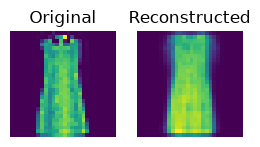

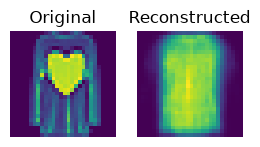

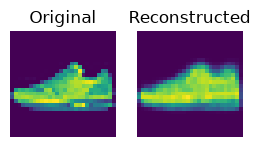

In [79]:
for idx in range(3):
    original = images_test[idx].cpu().numpy().reshape(28, 28)
    regenerated = reconstructed_test[idx].cpu().numpy().reshape(28, 28)
    plt.figure(figsize=(3, 3))
    plt.subplot(1, 2, 1)
    plt.imshow(original)
    plt.title("Original")
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(regenerated)
    plt.title("Reconstructed")
    plt.axis('off')


In [81]:
## Plot function
def plot_interpolation(img1,img2,img3,curr_class=""):
    # Give the tensor of size 784 as an input 
    img1 = img1.cpu().numpy().reshape(28, 28)
    img2 = img2.cpu().numpy().reshape(28, 28)
    img3 = img3.cpu().numpy().reshape(28, 28)
    plt.figure(figsize=(8, 3))
    plt.suptitle(f"Label: {curr_class}")

    plt.subplot(1, 3, 1)
    plt.imshow(img1)
    plt.title("Image 1")
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(img2)
    plt.title("Image 2")
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(img3)
    plt.title("(1-alpha)*Img1 + alpha*img2")
    plt.axis('off')
    return plt

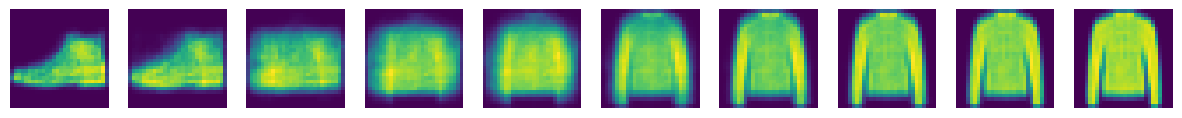

In [87]:
model.eval()

images, labels = next(iter(test_loader))
images = images.view(images.size(0), -1).to(device)

# Select two images
img1 = images[0:1]
img2 = images[1:2]

with torch.no_grad():
    mu1, _ = model.encode(img1)
    mu2, _ = model.encode(img2)

alphas = torch.linspace(0, 1, 10).to(device)

with torch.no_grad():
    interpolated_z = torch.cat([
        (1 - alpha) * mu1 + alpha * mu2
        for alpha in alphas
    ], dim=0)
    generated = model.decoder(interpolated_z)


fig, axes = plt.subplots(1, 10, figsize=(15, 2))

for i, ax in enumerate(axes):
    ax.imshow(generated[i].cpu().view(28, 28))
    ax.axis('off')

plt.show()

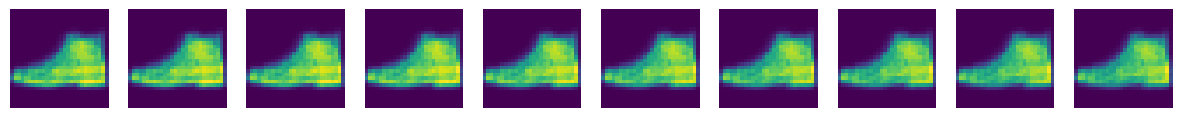

In [90]:
with torch.no_grad():
    mu, _ = model.encode(img1)

# Copy its latent representation
z = mu.clone()

# Vary only the first latent dimension
values = torch.linspace(-3, 3, 10).to(device)

generated = []

with torch.no_grad():
    for value in values:
        z_new = z.clone()
        z_new[0, 0] = value
        generated.append(model.decoder(z_new))

generated = torch.cat(generated, dim=0)

fig, axes = plt.subplots(1, 10, figsize=(15, 2))

for i, ax in enumerate(axes):
    ax.imshow(generated[i].cpu().view(28, 28))
    ax.axis('off')

In [96]:
model.eval()

with torch.no_grad():
    mu, _ = model.encode(img1)
    baseline = model.decoder(mu)

    sensitivity = []

    for dim in range(32):
        z_new = mu.clone()
        z_new[0, dim] = -100
        output = model.decoder(z_new)

        difference = torch.mean(torch.abs(output - baseline))
        sensitivity.append(difference.item())

for dim, score in sorted(
    enumerate(sensitivity), key=lambda x: x[1], reverse=True
):
    print(f"Dimension {dim}: {score:.6f}")

Dimension 12: 0.246286
Dimension 13: 0.234363
Dimension 2: 0.230366
Dimension 5: 0.227901
Dimension 7: 0.224789
Dimension 10: 0.221743
Dimension 6: 0.219710
Dimension 28: 0.219431
Dimension 22: 0.213809
Dimension 31: 0.211934
Dimension 15: 0.211358
Dimension 17: 0.208280
Dimension 1: 0.206194
Dimension 25: 0.205851
Dimension 29: 0.204636
Dimension 27: 0.201124
Dimension 14: 0.199499
Dimension 26: 0.197074
Dimension 30: 0.196203
Dimension 24: 0.195438
Dimension 8: 0.193989
Dimension 11: 0.193515
Dimension 9: 0.192949
Dimension 23: 0.192892
Dimension 21: 0.191126
Dimension 4: 0.190110
Dimension 16: 0.190094
Dimension 0: 0.187895
Dimension 18: 0.187446
Dimension 19: 0.184177
Dimension 20: 0.182928
Dimension 3: 0.174431


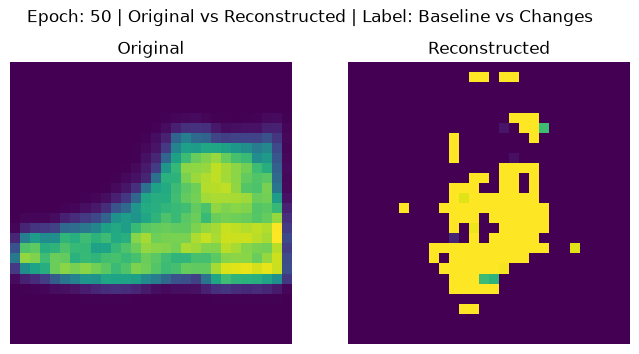

In [97]:
plt = plot_original_vs_reconstructed_image(baseline,output,"Baseline vs Changes")

In [92]:
all_mu = []

model.eval()

with torch.no_grad():
    for images, _ in test_loader:
        images = images.view(images.size(0), -1).to(device)
        mu, logvar = model.encode(images)
        all_mu.append(mu.cpu())

all_mu = torch.cat(all_mu, dim=0)

# Variance of each latent dimension across images
latent_variance = all_mu.var(dim=0)

for dim, var in enumerate(latent_variance):
    print(f"Dimension {dim}: {var.item():.6f}")

Dimension 0: 0.005575
Dimension 1: 0.005935
Dimension 2: 0.005430
Dimension 3: 1.472094
Dimension 4: 0.003168
Dimension 5: 0.004719
Dimension 6: 0.002757
Dimension 7: 0.003646
Dimension 8: 0.008832
Dimension 9: 1.094749
Dimension 10: 0.014918
Dimension 11: 0.003250
Dimension 12: 1.486991
Dimension 13: 0.004321
Dimension 14: 0.003935
Dimension 15: 0.022348
Dimension 16: 0.005718
Dimension 17: 0.017247
Dimension 18: 0.003904
Dimension 19: 1.100229
Dimension 20: 0.009924
Dimension 21: 1.277760
Dimension 22: 0.018594
Dimension 23: 0.019127
Dimension 24: 0.012523
Dimension 25: 0.010304
Dimension 26: 0.002169
Dimension 27: 0.009133
Dimension 28: 0.001632
Dimension 29: 0.010117
Dimension 30: 0.006511
Dimension 31: 0.003557
